# Контрольная работа №1. Проектирование и построение базы знаний
## Выполнение заданий 3 и 4: Моделирование онтологии и построение графа знаний
 
**Предметная область:** Программные библиотеки глубокого обучения экосистемы PyTorch  
**Основной класс в Wikidata:** `wd:Q29642950` Python library, связанный отношением `wdt:P1547 wd:Q47509047` зависит от PyTorch  


In [1]:
import subprocess
import sys
from pathlib import Path
from shutil import copy2
from tempfile import TemporaryDirectory

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdflib import Graph, RDF
from rdflib.compare import isomorphic

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)


<p class="task" id="3"></p>

## Задание 3. Разработка онтологии предметной области в Protégé

Онтология описывает программную экосистему библиотек глубокого обучения вокруг базового фреймворка PyTorch. Все классы и свойства размещены в пространстве имен `http://example.org/pytorch-ecosystem#` с префиксом `pte:`.

### Описание онтологии и выполнение требований

#### 1. Таксономия классов
Онтология включает 10 классов:
* `pte:SoftwareLibrary` — базовый класс программной библиотеки, эквивалентен `wd:Q188860` в Wikidata
  * `pte:MachineLearningLibrary` — библиотека машинного обучения, эквивалентен `wd:Q21169670` в Wikidata
    * `pte:ComputerVisionLibrary` — библиотека компьютерного зрения
    * `pte:NaturalLanguageProcessingLibrary` — библиотека обработки естественного языка и NLP
    * `pte:AudioProcessingLibrary` — библиотека обработки звука и речи
    * `pte:ProbabilisticAndGraphLibrary` — библиотека вероятностного и графового машинного обучения
    * `pte:OptimizationAndTrainingLibrary` — библиотека оптимизации и обучения
* `pte:SoftwareLicense` — лицензия на программное обеспечение, эквивалентен `wd:Q207621` в Wikidata
* `pte:SoftwareVersion` — версия программного обеспечения, эквивалентен `wd:Q341` в Wikidata
* `pte:Repository` — репозиторий исходного кода, эквивалентен `wd:Q474550` в Wikidata

#### 2. Объектные свойства
Свойства разделены на объектные и литеральные. Для каждого свойства заданы область определения `rdfs:domain` и область значений `rdfs:range`:
* `pte:dependsOnSoftware` — связывает библиотеку с другим программным обеспечением. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLibrary`. Эквивалентно свойству Wikidata `wdt:P1547`.
* `pte:hasLicense` — указывает лицензию библиотеки. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLicense`. Эквивалентно свойству Wikidata `wdt:P275`.
* `pte:hasPrimaryLicense` — функциональное свойство `owl:FunctionalProperty`, определяющее основную лицензию проекта. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLicense`. Является подсвойством `rdfs:subPropertyOf` для `pte:hasLicense`.
* `pte:hasRepository` — связывает библиотеку с репозиторием. Domain: `pte:SoftwareLibrary`, Range: `pte:Repository`. Эквивалентно свойству Wikidata `wdt:P1324`.
* `pte:hasSourceCodeRepository` — функциональное свойство `owl:FunctionalProperty`, определяющее основной репозиторий исходного кода. Domain: `pte:SoftwareLibrary`, Range: `pte:Repository`. Является подсвойством `rdfs:subPropertyOf` для `pte:hasRepository`.
* `pte:hasVersion` — связывает библиотеку с ее версией. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareVersion`.

#### 3. Свойства типа данных
Для каждого свойства заданы `rdfs:domain` и `rdfs:range`:
* `pte:libraryName` — текстовое название библиотеки. Domain: `pte:SoftwareLibrary`, Range: `xsd:string`.
* `pte:versionIdentifier` — функциональное свойство `owl:FunctionalProperty`, строковый идентификатор релиза. Domain: `pte:SoftwareVersion`, Range: `xsd:string`.
* `pte:releaseDate` — точная дата публикации релиза, временной квалификатор. Domain: `pte:SoftwareVersion`, Range: `xsd:dateTime`.
* `pte:versionType` — тип версии. Domain: `pte:SoftwareVersion`, Range: `xsd:string`.
* `pte:repositoryURL` — функциональное свойство `owl:FunctionalProperty`, веб-адрес репозитория. Domain: `pte:Repository`, Range: `xsd:anyURI`.
* `pte:licenseName` — функциональное свойство `owl:FunctionalProperty`, наименование лицензии. Domain: `pte:SoftwareLicense`, Range: `xsd:string`.
* `pte:versionCount` — функциональное свойство `owl:FunctionalProperty`, количество версий библиотеки. Domain: `pte:SoftwareLibrary`, Range: `xsd:integer`.

#### 4. Аннотации
Каждый класс и каждое свойство снабжены метками `rdfs:label` на русском и английском языках, а также развернутыми описаниями `rdfs:comment` на русском и английском языках.

#### 5. Связи эквивалентности с Wikidata
* Классы: `pte:SoftwareLibrary owl:equivalentClass wd:Q188860`, `pte:MachineLearningLibrary owl:equivalentClass wd:Q21169670`, `pte:SoftwareLicense owl:equivalentClass wd:Q207621`, `pte:SoftwareVersion owl:equivalentClass wd:Q341`, `pte:Repository owl:equivalentClass wd:Q474550`.
* Свойства: `pte:dependsOnSoftware owl:equivalentProperty wdt:P1547`, `pte:hasLicense owl:equivalentProperty wdt:P275`, `pte:hasRepository owl:equivalentProperty wdt:P1324`.

#### 6. Матрица использования элементов онтологии в 12 вопросах базы знаний

| Класс, свойство или источник | Тип элемента | Вопросы | Роль в ответе или модели |
| :--- | :--- | :--- | :--- |
| `pte:SoftwareLibrary` | Класс | В1–В6, В11–В12<br>(косвенно) | Область определения свойств библиотек в графовых запросах. |
| `pte:MachineLearningLibrary` | Класс | — | Общий суперкласс для специализированных библиотек машинного обучения. |
| `pte:ComputerVisionLibrary` | Класс | В4, В11 | Явный фильтр по классу библиотек компьютерного зрения. |
| `pte:NaturalLanguageProcessingLibrary` | Класс | В6 | Явный фильтр по классу библиотек обработки естественного языка. |
| `pte:ProbabilisticAndGraphLibrary` | Класс | В12 | Явный фильтр по классу вероятностных и графовых библиотек. |
| `pte:AudioProcessingLibrary`<br>`pte:OptimizationAndTrainingLibrary` | Классы | — | Классификация аудиобиблиотек и средств оптимизации и обучения. |
| `pte:SoftwareLicense` | Класс | В2, В4, В11, В12<br>(косвенно) | Класс объектов связи `pte:hasLicense`. |
| `pte:SoftwareVersion` | Класс | В5<br>(косвенно) | Класс узлов релизов, к которым ведёт `pte:hasVersion`. |
| `pte:Repository` | Класс | В4, В6<br>(косвенно) | Класс промежуточных узлов на пути от библиотеки к URL. |
| `pte:libraryName` | Datatype | В1, В3–В6, В11, В12 | Имя библиотеки в результате запроса. |
| `pte:versionCount` | Datatype | В1, В3, В11, В12 | Фильтр по числу версий в В1 и В12. Сортировка в В3 и В11. |
| `pte:hasLicense` | Object | В2, В4, В11, В12 | Связь для подсчёта по лицензиям в В2 и отбора по конкретной лицензии в В4, В11 и В12. |
| `pte:licenseName` | Datatype | В2 | Группировка по названию лицензии. |
| `pte:dependsOnSoftware` | Object | В4 | Проверка зависимости библиотеки от PyTorch. |
| `pte:hasRepository`<br>`pte:repositoryURL` | Object / Datatype | В4, В6 | Путь из двух рёбер от библиотеки к URL репозитория. |
| `pte:hasVersion`<br>`pte:releaseDate` | Object / Datatype | В5 | Переход к релизу, фильтр за 2023 год и сортировка по дате публикации. |
| `pte:versionIdentifier` | Datatype | В5 | Строковый идентификатор релиза. В5 возвращает его и использует для сортировки при равных дате и названии. |
| `owl:sameAs` | Свойство OWL | В11, В12 | QID выбранной графом библиотеки связывает результат с записью корпуса и README. |
| `pte:hasPrimaryLicense` | Object | — | Функциональное подсвойство для единственной основной лицензии проекта. |
| `pte:hasSourceCodeRepository` | Object | — | Функциональное подсвойство для единственного основного репозитория проекта. |
| `pte:versionType` | Datatype | — | Статус релиза, например stable. Свойство позволяет отбирать версии по статусу независимо от даты. |
| README / data/corpus.jsonl | Текстовый источник | В7–В12 | В7–В10 используют текст по заранее заданному QID. В11–В12 читают текст после выбора библиотеки графом. |


In [2]:
project = Path.cwd()
if project.name == "Резы":
    project = project.parent

with TemporaryDirectory(prefix="wikibase-") as tmp:
    work = Path(tmp)
    (work / "data").mkdir()
    copy2(project / "data" / "libraries_metadata.json", work / "data")
    subprocess.run(
        [sys.executable, "-X", "utf8", str(project / "scripts" / "02_build_ontology_and_graph.py")],
        cwd=work,
        check=True,
        stdout=subprocess.DEVNULL,
    )
    ontology = Graph().parse(work / "ontology.ttl", format="turtle")
    kg = Graph().parse(work / "knowledge_graph.ttl", format="turtle")

reference_ontology = Graph().parse(project / "ontology.ttl", format="turtle")
assert isomorphic(ontology, reference_ontology), "Собранная онтология отличается от ontology.ttl"
print(f"Онтология совпадает с ontology.ttl ({len(ontology)} троек).")


Онтология совпадает с ontology.ttl (155 троек).


<p class="task" id="4"></p>

## Задание 4. Выгрузка данных из Wikidata и построение графа знаний

В рамках Задания 4 решаются следующие задачи:
1. Чтение сохранённых метаданных 52 библиотек из `data/libraries_metadata.json`
2. Преобразование сущностей в экземпляры классов собственной онтологии `pte:`
3. Проставление связей `owl:sameAs` для библиотек и лицензий с известными идентификаторами Wikidata
4. Формирование связей с версиями, лицензиями и репозиториями
5. Расчет статистики графа знаний: число троек, сущностей, разбивка по классам и свойствам
6. Сборка Turtle во временном каталоге скриптом `scripts/02_build_ontology_and_graph.py` и сверка с `knowledge_graph.ttl` в репозитории
7. Верификация графа целевыми SPARQL-запросами


In [3]:
reference_graph = Graph().parse(project / "knowledge_graph.ttl", format="turtle")
assert isomorphic(kg, reference_graph), "Собранный граф отличается от knowledge_graph.ttl"
print(f"Граф совпадает с knowledge_graph.ttl ({len(kg)} троек).")


Граф совпадает с knowledge_graph.ttl (9302 троек).


### 4.1. Верификация наличия `owl:sameAs` для сущностей домена

Связи `owl:sameAs` указаны для всех 53 библиотек, включая PyTorch, и для четырёх лицензий с известными идентификаторами Wikidata.


In [4]:
q_sameas = """
PREFIX owl: <http://www.w3.org/2002/07/owl#>
PREFIX pte: <http://example.org/pytorch-ecosystem#>

SELECT ?entity ?name ?sameAs WHERE {
  ?entity owl:sameAs ?sameAs .
  OPTIONAL { ?entity pte:libraryName ?name . }
  OPTIONAL { ?entity pte:licenseName ?name . }
}
ORDER BY ?name ?entity
"""

res_sameas = kg.query(q_sameas)
sameas_list = []
for row in res_sameas:
    e_name = str(row["entity"]).split("#")[-1]
    lbl = str(row["name"]) if row["name"] else e_name
    wd_target = str(row["sameAs"])
    sameas_list.append({
        "Сущность в графе": f"pte:{e_name}",
        "Название или метка": lbl,
        "owl:sameAs URI в Wikidata": wd_target
    })

df_sameas = pd.DataFrame(sameas_list)
display(df_sameas.head(15))


,Сущность в графе,Название или метка,owl:sameAs URI в Wikidata
0,pte:License_BSD-2-Clause,2-clause BSD License,http://www.wikidata.org/entity/Q191244
1,pte:License_BSD-3-Clause,3-clause BSD License,http://www.wikidata.org/entity/Q180189
2,pte:License_Apache-2.0,Apache Software License 2.0,http://www.wikidata.org/entity/Q616523
3,pte:License_MIT,MIT License,http://www.wikidata.org/entity/Q334660
4,pte:Lib_PyKEEN_Q96631404,PyKEEN,http://www.wikidata.org/entity/Q96631404
5,pte:PyTorch,PyTorch,http://www.wikidata.org/entity/Q47509047
6,pte:Lib_PyTorch_Lightning_Q85847011,PyTorch Lightning,http://www.wikidata.org/entity/Q85847011
7,pte:Lib_Pyserini_Q136092892,Pyserini,http://www.wikidata.org/entity/Q136092892
8,pte:Lib_STonKGs_Q116908797,STonKGs,http://www.wikidata.org/entity/Q116908797
9,pte:Lib_Stanza_Q120550372,Stanza,http://www.wikidata.org/entity/Q120550372


### 4.2. Статистика графа знаний: тройки, сущности, разбивка по классам и свойствам

Количественные показатели графа знаний включают общее число троек, уникальных субъектов, а также распределение по классам и предикатам.


,Метрика,Значение
0,Общее количество троек,9302
1,Количество уникальных субъектов,1834
2,Количество уникальных предикатов,17
3,Количество уникальных объектов,3709


,Класс,Количество экземпляров
0,SoftwareVersion,1719
1,Repository,53
2,ComputerVisionLibrary,12
3,NaturalLanguageProcessingLibrary,12
4,OptimizationAndTrainingLibrary,11
5,MachineLearningLibrary,10
6,SoftwareLicense,9
7,ProbabilisticAndGraphLibrary,8


,Предикат,Количество троек
0,type,1834
1,hasVersion,1719
2,releaseDate,1719
3,versionIdentifier,1719
4,versionType,1719
5,sameAs,57
6,hasLicense,53
7,hasPrimaryLicense,53
8,hasRepository,53
9,hasSourceCodeRepository,53


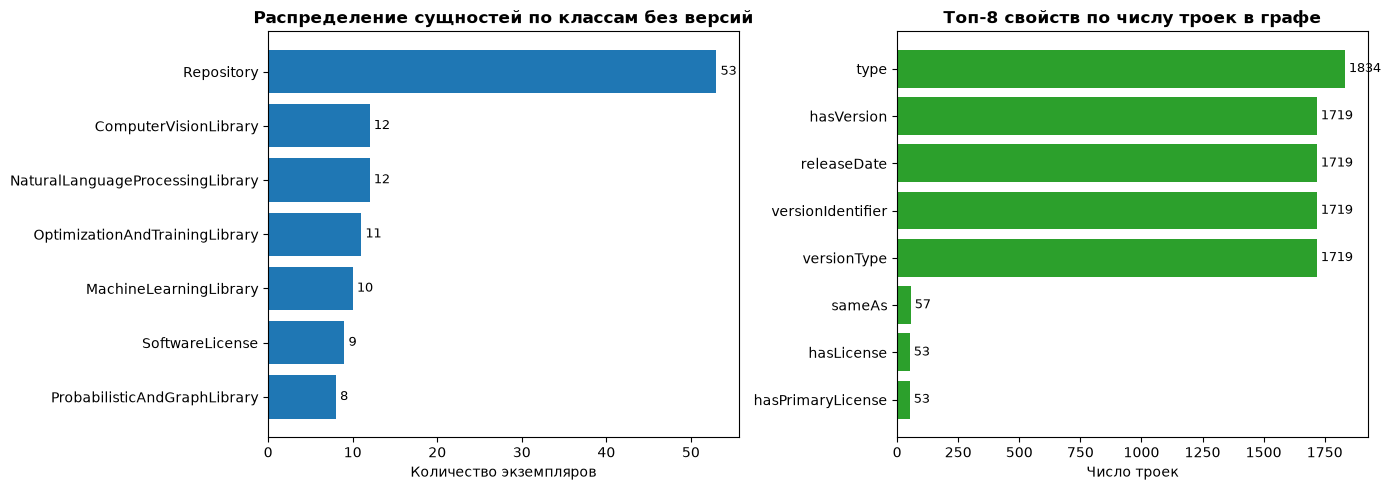

In [5]:
classes_stat = {}
for s, p, o in kg.triples((None, RDF.type, None)):
    c_name = str(o).split("#")[-1]
    classes_stat[c_name] = classes_stat.get(c_name, 0) + 1

df_class_stat = pd.DataFrame(list(classes_stat.items()), columns=["Класс", "Количество экземпляров"]).sort_values(["Количество экземпляров", "Класс"], ascending=[False, True]).reset_index(drop=True)

props_stat = {}
for s, p, o in kg:
    p_name = str(p).split("#")[-1] if "#" in str(p) else str(p).split("/")[-1]
    props_stat[p_name] = props_stat.get(p_name, 0) + 1

df_prop_stat = pd.DataFrame(list(props_stat.items()), columns=["Предикат", "Количество троек"]).sort_values(["Количество троек", "Предикат"], ascending=[False, True]).reset_index(drop=True)

summary_stats = [
    {"Метрика": "Общее количество троек", "Значение": len(kg)},
    {"Метрика": "Количество уникальных субъектов", "Значение": len(set(kg.subjects()))},
    {"Метрика": "Количество уникальных предикатов", "Значение": len(set(kg.predicates()))},
    {"Метрика": "Количество уникальных объектов", "Значение": len(set(kg.objects()))}
]
df_summary = pd.DataFrame(summary_stats)

display(df_summary)
display(df_class_stat)
display(df_prop_stat)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

df_classes_plot = df_class_stat[df_class_stat["Класс"] != "SoftwareVersion"]
bars1 = ax1.barh(df_classes_plot["Класс"], df_classes_plot["Количество экземпляров"], color="#1f77b4")
ax1.set_title("Распределение сущностей по классам без версий", fontsize=12, fontweight="bold")
ax1.set_xlabel("Количество экземпляров")
ax1.invert_yaxis()
for bar in bars1:
    ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())}", va='center', fontsize=9)

df_props_top = df_prop_stat.head(8)
bars2 = ax2.barh(df_props_top["Предикат"], df_props_top["Количество троек"], color="#2ca02c")
ax2.set_title("Топ-8 свойств по числу троек в графе", fontsize=12, fontweight="bold")
ax2.set_xlabel("Число троек")
ax2.invert_yaxis()
for bar in bars2:
    ax2.text(bar.get_width() + 15, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


### 4.3. Верификация графа знаний целевыми SPARQL-запросами

Проверка использует шесть запросов из задания 2.

1. **В1.** У каких библиотек экосистемы PyTorch в графе зарегистрировано более 20 версий? Укажите названия и число версий.
2. **В2.** Сколько различных библиотек связано в графе с каждой лицензией?
3. **В3.** Какие пять библиотек занимают первые места по числу зарегистрированных в графе версий? При равенстве расположите их по названию.
4. **В4.** Какие библиотеки компьютерного зрения зависят от PyTorch и распространяются по лицензии Apache License 2.0? Укажите ссылки на их репозитории.
5. **В5.** Какие десять различных сочетаний библиотеки, номера версии и даты выпуска идут первыми по дате публикации в 2023 году? При равенстве дат отсортируйте по названию библиотеки и номеру версии как строке.
6. **В6.** Какие записи библиотек классифицированы в графе как библиотеки обработки естественного языка (NLP)? Укажите адреса их репозиториев.


In [6]:
queries_test = [
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?name ?count WHERE {
      ?library pte:libraryName ?name ; pte:versionCount ?count .
      FILTER(?count > 20)
    }
    ORDER BY DESC(?count) LCASE(STR(?name)) ?name
    """, ["Название библиотеки", "Число версий"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?licenseName (COUNT(DISTINCT ?library) AS ?count) WHERE {
      ?library pte:hasLicense ?license .
      ?license pte:licenseName ?licenseName .
    }
    GROUP BY ?licenseName
    ORDER BY DESC(?count) ?licenseName
    """, ["Лицензия", "Количество библиотек"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?name ?count WHERE {
      ?library pte:libraryName ?name ; pte:versionCount ?count .
    }
    ORDER BY DESC(?count) LCASE(STR(?name)) ?name
    LIMIT 5
    """, ["Библиотека", "Число версий"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT DISTINCT ?name ?repoUrl WHERE {
      ?library a pte:ComputerVisionLibrary ;
               pte:libraryName ?name ;
               pte:dependsOnSoftware pte:PyTorch ;
               pte:hasLicense pte:License_Apache_License_2_0 ;
               pte:hasRepository/pte:repositoryURL ?repoUrl .
    }
    ORDER BY ?name ?repoUrl
    """, ["Библиотека компьютерного зрения", "URL репозитория"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
    SELECT DISTINCT ?name ?version ?date WHERE {
      ?library pte:libraryName ?name ; pte:hasVersion ?release .
      ?release pte:versionIdentifier ?version ; pte:releaseDate ?date .
      FILTER(?date >= "2023-01-01T00:00:00Z"^^xsd:dateTime &&
             ?date < "2024-01-01T00:00:00Z"^^xsd:dateTime)
    }
    ORDER BY ?date ?name ?version
    LIMIT 10
    """, ["Библиотека", "Версия", "Дата релиза в 2023 году"]),
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT DISTINCT ?name ?repoUrl WHERE {
      ?library a pte:NaturalLanguageProcessingLibrary ;
               pte:libraryName ?name ;
               pte:hasRepository/pte:repositoryURL ?repoUrl .
    }
    ORDER BY ?name ?repoUrl
    """, ["Библиотека NLP", "URL репозитория"]),
]

for q_str, col_names in queries_test:
    res = kg.query(q_str)
    rows = [[str(val) for val in r] for r in res]
    df_q = pd.DataFrame(rows, columns=col_names)
    display(df_q)


,Название библиотеки,Число версий
0,pytorch-pretrained-bert,242
1,pytorch-transformers,242
2,PyTorch Lightning,208
3,accelerate,67
4,torchmetrics,63
5,open-clip-torch,57
6,Pyserini,57
7,botorch,55
8,rotary-embedding-torch,53
9,timm,51


,Лицензия,Количество библиотек
0,лицензия MIT,23
1,Apache License 2.0,21
2,модифицированная лицензия BSD,6
3,2-пунктная лицензия BSD,2
4,Free To Use But Restricted,1


,Библиотека,Число версий
0,pytorch-pretrained-bert,242
1,pytorch-transformers,242
2,PyTorch Lightning,208
3,accelerate,67
4,torchmetrics,63


,Библиотека компьютерного зрения,URL репозитория
0,effdet,https://github.com/rwightman/efficientdet-pytorch
1,gfpgan,https://github.com/TencentARC/GFPGAN
2,kornia,https://github.com/kornia/kornia
3,timm,https://github.com/huggingface/pytorch-image-models


,Библиотека,Версия,Дата релиза в 2023 году
0,pyro-ppl,1.8.4,2023-01-03T00:00:00+00:00
1,gpytorch,1.9.1,2023-01-04T00:00:00+00:00
2,open-clip-torch,2.9.2,2023-01-05T00:00:00+00:00
3,botorch,0.8.1,2023-01-06T00:00:00+00:00
4,open-clip-torch,2.9.3,2023-01-09T00:00:00+00:00
5,PyTorch Lightning,1.9.0,2023-01-17T00:00:00+00:00
6,nerfacc,0.3.3,2023-01-18T00:00:00+00:00
7,open-clip-torch,2.10.0,2023-01-23T00:00:00+00:00
8,open-clip-torch,2.10.1,2023-01-24T00:00:00+00:00
9,pytorch-pretrained-bert,4.26.0,2023-01-25T00:00:00+00:00


,Библиотека NLP,URL репозитория
0,STonKGs,https://github.com/stonkgs/stonkgs
1,Stanza,https://github.com/stanfordnlp/stanza
2,allennlp,https://github.com/allenai/allennlp
3,attacut,https://github.com/PyThaiNLP/attacut
4,bert-score,https://github.com/Tiiiger/bert_score
5,flair,https://github.com/flairNLP/flair
6,fschat,https://github.com/lm-sys/fastchat
7,peft,https://github.com/huggingface/peft
8,pytorch-pretrained-bert,https://github.com/huggingface/transformers
9,pytorch-transformers,https://github.com/huggingface/transformers


## Итоги выполнения заданий 3 и 4

1. Задание 3:
   - Разработана OWL-онтология предметной области в пространстве имен `http://example.org/pytorch-ecosystem#`
   - Реализована таксономия из 10 классов, включая предметные категории компьютерного зрения, обработки естественного языка, вероятностных и графовых моделей, оптимизации и распределенного обучения
   - Свойства разделены на объектные и литеральные, у каждого свойства специфицированы `rdfs:domain` и `rdfs:range`
   - Объявлены функциональные свойства `owl:FunctionalProperty`: `hasPrimaryLicense`, `hasSourceCodeRepository`, `versionIdentifier`, `repositoryURL`, `licenseName`, `versionCount`
   - Все сущности снабжены двуязычными аннотациями `rdfs:label` и подробными комментариями `rdfs:comment` на русском и английском языках
   - Зафиксированы соответствия `owl:equivalentClass` и `owl:equivalentProperty` к сущностям Wikidata
   - Построена матрица покрытия 12 вопросов доменными элементами онтологии
   - Текст онтологии приведен в файле `ontology.ttl`

2. Задание 4:
   - Граф собран из сохранённых метаданных 52 библиотек экосистемы и включает центральный узел PyTorch
   - Для 53 библиотек и четырёх лицензий проверены связи `owl:sameAs` с Wikidata
   - Собранный граф включает 9 302 троек и 1 834 уникальных субъектов
   - Рассчитана и визуализирована подробная статистика по классам и предикатам
   - Работоспособность графа подтверждена серией целевых SPARQL-запросов
   - Граф, собранный во временном каталоге, совпадает с `knowledge_graph.ttl` в репозитории
